# Social dilemma {#sec-socialdilemma}

Here, we consider two social dilemmas: the stag-hunt game and the prisoner's dilemma.

The stag-hunt game is a type of social dilemma where two or more agents must coordinate on the best action. Hence, it is often called a "coordination problem". In our version, we consider two agents who must take one of two actions: cooperate ($c$) or defect ($d$). 

If both agents cooperate, they get a payoff $R$ (called "reward"). If they both defect, they get a payoff $P$ (called "punishment"). If one cooperates and the other defects, the cooperator gets a payoff $S$ (called "sucker") and the defector, a payoff $T$ (called "temptation"). In a stag-hunt game, $R > T > P > S$. This means the agents' main challenge is coordination: cooperating at the same time in order to get the maximum reward. 

Note that, if $T > R > P > S$, the game becomes a prisoner's dilemma: both agents are incentivized to defect, because the temptation is now the maximum payoff. 

The structure of a social dilemma is shown below.

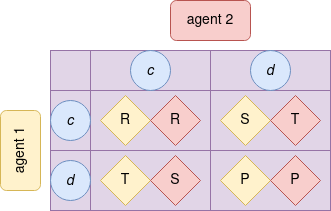

Let's implement a social dilemma.

First, we import what we need:

In [ ]:
 #| default_exp Environments/SocialDilemma

In [ ]:
 #| hide
# Imports for the nbdev development environment
import nbdev
from nbdev.showdoc import *
from fastcore.basics import patch

In [ ]:
# imports for testing
import matplotlib.pyplot as plt
import numpy as np

# test agent
from pyCRLD.Agents.Base import abase
from pyCRLD.Agents.StrategySARSA import stratSARSA

# utils
from pyCRLD.Utils import FlowPlot as fp
from pyDDRL.Utils.Trajectories1D import trajectories_1D 
from pyDDRL.Utils.PhasePlot import phaseplot

In [ ]:
 #| export
from pyCRLD.Environments.Base import ebase

from fastcore.utils import *
from fastcore.test import *

import numpy as np

In [ ]:
 #| export
class SocialDilemma(ebase):
    """
    Symmetric 2-agent 2-action Social Dilemma Matrix Game.
    """ 

    def __init__(self,
                 R:float,  # reward of mutual cooperation
                 T:float,  # temptation of unilateral defection 
                 S:float,  # sucker's payoff of unilateral cooperation
                 P:float): # punsihment of mutual defection
        self.N = 2
        self.M = 2
        self.Z = 1
        
        self.disttype = None

        self.Re = R
        self.Te = T
        self.Su = S    
        self.Pu = P

        self.state = 0 # inital state
        super().__init__()

In [ ]:
 #| export
@patch
def TransitionTensor(self:SocialDilemma):
    """Get the Transition Tensor."""
    Tsas = np.ones((self.Z, self.M, self.M, self.Z))             
    return Tsas

In [ ]:
 #| export
@patch
def RewardTensor(self:SocialDilemma):
    """Get the Reward Tensor R[i,s,a1,...,aN,s']."""

    R = np.zeros((2, self.Z, 2, 2, self.Z))

    R[0, 0, :, :, 0] = [[self.Re , self.Su],
                        [self.Te , self.Pu]]
    R[1, 0, :, :, 0] = [[self.Re , self.Te],
                        [self.Su , self.Pu]]

    return R

In [ ]:
 #| export
@patch
def actions(self:SocialDilemma):
    """The action sets"""
    return [['c', 'd'] for _ in range(self.N)]

In [ ]:
 #| export
@patch
def states(self:SocialDilemma):
    """The states set"""
    return ['.'] 

In [ ]:
 #| export
@patch
def id(self:SocialDilemma):
    """
    Returns id string of environment
    """
    # Default
    id = f"{self.__class__.__name__}_"+\
        f"{self.Te}_{self.Re}_{self.Pu}_{self.Su}"
    return id

## Example 

We implement both a stag-hunt game and a prisoner's dilemma. 

In [ ]:
# Define environments
envSH = SocialDilemma(R=3, T=1, P=0, S=-2)  # stag hunt
envPD = SocialDilemma(R=1, T=3, P=0, S=-2)  # prisoner's dilemma

Now, we define an agent-environment interface comprised of a SARSA agent playing the aforementioned tasks. This agent has a learning rate $\alpha=0.1$, a discount factor $\gamma = 0.9$, and a choice intensity $\beta = 50$. 

In [ ]:
# Agent-environment interface
aeiSH = stratSARSA(envSH,
                   learning_rates=0.1,
                   discount_factors=0.9,
                   choice_intensities=50.,
                   use_prefactor=True)

aeiPD = stratSARSA(envPD,
                   learning_rates=0.1,
                   discount_factors=0.9,
                   choice_intensities=50.,
                   use_prefactor=True)

No GPU/TPU found, falling back to CPU. (Set TF_CPP_MIN_LOG_LEVEL=0 and rerun for more info.)


We plot the agent's deterministic trajectories in phase space on the flow plots below:

Text(0, 0.5, 'prob. agent 2 cooperates')

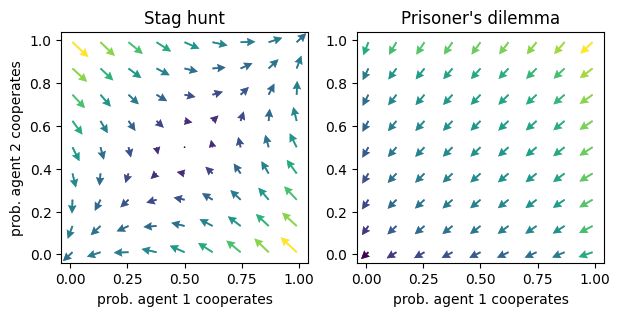

In [ ]:
# Figure
x = ([0], [0], [0])  # (i,s,a) to plot along the x-axis
y = ([1], [0], [0])  # (i,s,a) to plot along the y-axis

# Plot flow plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7, 3))
fp.plot_strategy_flow(aeiSH, x, y, flowarrow_points = np.linspace(0.01 ,0.99, 9), 
                      NrRandom=16, axes=ax1)
fp.plot_strategy_flow(aeiPD, x, y, flowarrow_points = np.linspace(0.01 ,0.99, 9), 
                      NrRandom=16, axes=ax2)
ax1.set_title("Stag hunt")
ax2.set_title("Prisoner's dilemma")
ax1.set_xlabel("prob. agent 1 cooperates")
ax2.set_xlabel("prob. agent 1 cooperates")
ax1.set_ylabel("prob. agent 2 cooperates")

In [ ]:
 #| hide
nbdev.export.nb_export("03.03_SocialDilemma.ipynb", "")